# 02 · Optimizers: SGD, momentum, Adam, AdamW

**Goal:** write the four optimizers by hand, prove they match PyTorch, *see* how they move on a loss surface, and
understand the one subtle difference between **Adam** and **AdamW**. Everything runs on CPU in seconds.

**Recap.** Backprop gives us the gradient `g` = the direction in which the loss increases fastest. An **optimizer**
is the rule that converts gradients into weight changes. The hand-written versions are in `src/optim_scratch.py`
(open it side by side with this notebook), the PyTorch ones are built by `src/optim.py`.

In [1]:
import sys, pathlib

# Make `import src...` work whether this notebook is opened from learn/ or from the repo root.
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("torch", torch.__version__, "| repo root:", ROOT)
from src.optim_scratch import SGDScratch, AdamScratch
from src.optim import build_optimizer, OPTIMIZER_NAMES
print("optimizers wired into train.py:", OPTIMIZER_NAMES)

torch 2.15.0+cpu | repo root: D:\ali\Programming\D&D
optimizers wired into train.py: ('sgd', 'sgd_momentum', 'sgd_nesterov', 'adam', 'adamw')


## 1. The four update rules

| Optimizer | Rule (per weight `w`, gradient `g`) | Intuition |
|---|---|---|
| **SGD** | `w -= lr * g` | walk downhill |
| **SGD + momentum** | `v = μ·v + g;  w -= lr * v` | a heavy ball: keeps rolling in a consistent direction, cancels zig-zags |
| **Nesterov** | `w -= lr * (g + μ·v)` | momentum that "looks ahead" |
| **Adam** | `m = β1·m + (1-β1)·g;  v = β2·v + (1-β2)·g²;  w -= lr · m̂ / (√v̂ + ε)` | momentum **and** a separate step size per weight |
| **AdamW** | same as Adam, plus `w *= 1 - lr·wd` | Adam with *correct* weight decay |

`μ` (momentum) is usually 0.9. Adam's `m` is a running average of gradients (direction), `v` a running average of
*squared* gradients (how big they typically are). Dividing by `√v̂` gives every weight a step of roughly `lr` regardless of
its gradient's scale.

## 2. Prove our hand-written versions are correct

We optimise a small nonlinear function of two parameter tensors with PyTorch's optimizer and with ours, from the same
starting point, in float64, and check that **every one of 50 steps** matches.

In [2]:
def make_problem():
    w = torch.tensor([0.5, -1.0, 2.0], dtype=torch.float64, requires_grad=True)
    b = torch.tensor([0.3], dtype=torch.float64, requires_grad=True)
    return [w, b]

x = torch.tensor([1.0, 2.0, -1.5], dtype=torch.float64)

def loss_fn(params):
    w, b = params
    return ((w * x).sum() + b - 3.0) ** 2 + 0.1 * (w ** 2).sum() + torch.sin(w).sum()

def run(opt_ctor, steps=50):
    params = make_problem()
    opt = opt_ctor(params)
    history = []
    for _ in range(steps):
        opt.zero_grad()
        loss_fn(params).backward()
        opt.step()
        history.append(torch.cat([p.detach().flatten() for p in params]).clone())
    return torch.stack(history)

wd = 0.05
pairs = {
    "SGD":              (lambda p: torch.optim.SGD(p, lr=0.01, weight_decay=wd),
                         lambda p: SGDScratch(p, lr=0.01, weight_decay=wd)),
    "SGD + momentum":   (lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, weight_decay=wd),
                         lambda p: SGDScratch(p, lr=0.01, momentum=0.9, weight_decay=wd)),
    "Nesterov":         (lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, nesterov=True, weight_decay=wd),
                         lambda p: SGDScratch(p, lr=0.01, momentum=0.9, nesterov=True, weight_decay=wd)),
    "Adam (L2)":        (lambda p: torch.optim.Adam(p, lr=0.05, weight_decay=wd),
                         lambda p: AdamScratch(p, lr=0.05, weight_decay=wd)),
    "AdamW (decoupled)":(lambda p: torch.optim.AdamW(p, lr=0.05, weight_decay=wd),
                         lambda p: AdamScratch(p, lr=0.05, weight_decay=wd, decoupled=True)),
}
for name, (theirs, ours) in pairs.items():
    a, b = run(theirs), run(ours)
    err = (a - b).abs().max().item()
    assert err < 1e-8, (name, err)
    print(f"{name:<20} max |torch - scratch| over 50 steps = {err:.1e}   OK")

SGD                  max |torch - scratch| over 50 steps = 0.0e+00   OK
SGD + momentum       max |torch - scratch| over 50 steps = 0.0e+00   OK
Nesterov             max |torch - scratch| over 50 steps = 0.0e+00   OK


Adam (L2)            max |torch - scratch| over 50 steps = 2.2e-16   OK
AdamW (decoupled)    max |torch - scratch| over 50 steps = 8.9e-16   OK


**What to observe.** All five agree to ~1e-15. There is no magic in `torch.optim`: each optimizer is a handful
of lines operating on tensors.

## 3. Watching them move: a narrow ravine

`f(x, y) = ½ (x² + 100·y²)` is a long, narrow valley: very steep in `y` (curvature 100), nearly flat along `x`
(curvature 1). The minimum is at (0, 0). Real loss surfaces have exactly this shape in many directions at once, which
is why optimisers matter. Each optimizer below uses a learning rate close to the **largest value that still works for it**
(a fair fight), found by trying a few values.

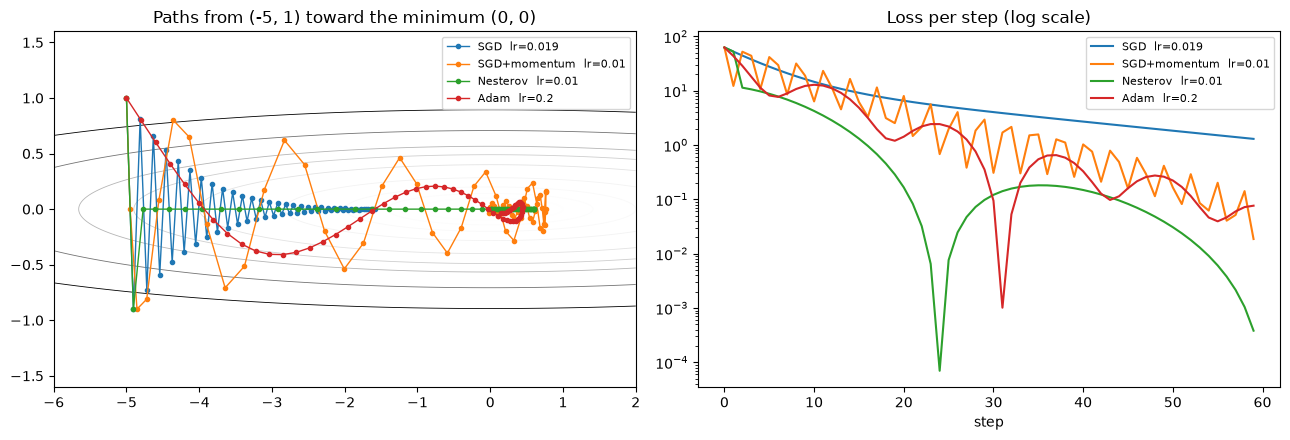

In [3]:
def ravine(p):
    return 0.5 * (p[0] ** 2 + 100.0 * p[1] ** 2)

def trajectory(opt_ctor, start=(-5.0, 1.0), steps=60):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_ctor([p])
    path, losses = [p.detach().clone()], []
    for _ in range(steps):
        opt.zero_grad()
        loss = ravine(p)
        loss.backward()
        opt.step()
        losses.append(loss.item())
        path.append(p.detach().clone())
    return torch.stack(path), losses

runs = {
    "SGD  lr=0.019":             lambda p: torch.optim.SGD(p, lr=0.019),     # just under the 2/100 stability limit
    "SGD+momentum  lr=0.01":     lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    "Nesterov  lr=0.01":         lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, nesterov=True),
    "Adam  lr=0.2":              lambda p: torch.optim.Adam(p, lr=0.2),
}
results = {name: trajectory(ctor) for name, ctor in runs.items()}

xs, ys = torch.meshgrid(torch.linspace(-6, 2, 300), torch.linspace(-1.6, 1.6, 300), indexing="xy")
zs = 0.5 * (xs ** 2 + 100 * ys ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].contour(xs, ys, zs, levels=[0.05, 0.2, 0.5, 1, 2, 4, 8, 12, 16, 25, 40], cmap="Greys", linewidths=0.6)
for name, (path, _) in results.items():
    ax[0].plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1, label=name)
ax[0].set_title("Paths from (-5, 1) toward the minimum (0, 0)"); ax[0].legend(fontsize=8)
for name, (_, losses) in results.items():
    ax[1].semilogy(losses, label=name)
ax[1].set_title("Loss per step (log scale)"); ax[1].set_xlabel("step"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to observe** (the loss plot on the right, log scale, tells the story; the exact numbers you see are in the printout below).

* **Plain SGD** bounces across the steep `y` direction while crawling along the flat `x` direction. Its learning rate is
  **capped by the steepest direction** (`lr < 2/100 = 0.02`; any larger and it diverges), and that small LR is far too
  timid for the flat direction: after 60 steps it has covered only about two thirds of the way along `x` (loss still ~1.3).
* **Momentum** keeps a velocity: the `y` bounces cancel out while the consistent push along `x` accumulates. It ends with a loss
  tens of times lower than SGD. The price: it overshoots and swings back (a ball with inertia), so its curve is noisy.
* **Nesterov** computes the gradient *after* the momentum step ("look ahead"), so it brakes earlier and swings less. But its
  stability limit is a bit tighter: try `lr=0.015` and watch it diverge.
* **Adam** gives `x` and `y` steps of a similar size (it divides by each coordinate's typical gradient), so it is not held back
  by the steep direction and reaches the valley floor fast. With a **constant** LR its steps do not shrink, so it keeps
  circling the minimum: one reason we pair it with an LR schedule (notebook 03).

In [4]:
for name, (_, losses) in results.items():
    print(f"{name:<24} loss after 20 / 40 / 60 steps: {losses[19]:9.4f} {losses[39]:9.4f} {losses[59]:9.4f}")

SGD  lr=0.019            loss after 20 / 40 / 60 steps:    6.9426    2.8131    1.2999
SGD+momentum  lr=0.01    loss after 20 / 40 / 60 steps:    2.5341    0.2597    0.0186
Nesterov  lr=0.01        loss after 20 / 40 / 60 steps:    0.2880    0.1603    0.0004
Adam  lr=0.2             loss after 20 / 40 / 60 steps:    1.2004    0.4666    0.0766


## 4. Adam vs AdamW: what "decoupled weight decay" means

**Weight decay** pulls weights toward 0 to discourage huge weights (regularisation). There are two ways to do it in Adam:

* **Adam + L2**: add `wd·w` to the gradient, *then* run Adam. But Adam divides by `√v̂`, so the decay is divided too:
  weights whose gradients are large end up barely decayed, weights with tiny gradients are decayed a lot.
* **AdamW**: shrink the weights directly (`w *= 1 - lr·wd`), outside the adaptive part. Every weight decays at the same
  relative rate.

Experiment: minimise the linear loss `c·w` for three weights whose gradient scales are `c = 0.1, 1, 10`. With constant
gradients, decay is the only thing that stops `w` from running away. *Predict* the final values first:

* AdamW's step is about `lr` regardless of `c`, so the balance with decay gives `|w| ≈ 1/wd` for **all three**.
* Adam+L2 stops when the gradient `c + wd·w` is zero, i.e. `|w| = c/wd`: **three different values**.

In [5]:
def run_linear(opt_ctor, c=(0.1, 1.0, 10.0), steps=4000):
    w = torch.zeros(3, dtype=torch.float64, requires_grad=True)
    cc = torch.tensor(c, dtype=torch.float64)
    opt = opt_ctor([w])
    for _ in range(steps):
        opt.zero_grad()
        (cc * w).sum().backward()
        opt.step()
    return w.detach()

wd, lr = 1.0, 0.05
w_adam  = run_linear(lambda p: AdamScratch(p, lr=lr, weight_decay=wd, decoupled=False))
w_adamw = run_linear(lambda p: AdamScratch(p, lr=lr, weight_decay=wd, decoupled=True))
print("gradient scale c      :", [0.1, 1.0, 10.0])
print("Adam  + L2   final w  :", [round(v, 3) for v in w_adam.tolist()],  " <- depends on c")
print("AdamW        final w  :", [round(v, 3) for v in w_adamw.tolist()], " <- ~ -1/wd for every c")

gradient scale c      : [0.1, 1.0, 10.0]
Adam  + L2   final w  : [-0.1, -1.0, -10.0]  <- depends on c
AdamW        final w  : [-1.0, -1.0, -1.0]  <- ~ -1/wd for every c


**Take-away.** With plain Adam the *effective* regularisation depends on the gradient scale of each weight, which is
accidental and hard to tune. AdamW makes `weight_decay` mean what it says, which is why it is the default for
fine-tuning and transformers.

## 5. Which one should I use?

These are rules of thumb, not laws. The honest answer is "try two and measure": that is what `experiments/compare.py` does.

* **AdamW (lr ≈ 1e-4 to 1e-3) + warmup + cosine decay**: robust default, forgiving about the LR; great for fine-tuning.
* **SGD + momentum (0.9) + cosine/step decay**: often reaches slightly better final accuracy on image CNNs when
  trained long and tuned well, but is more sensitive to the learning rate.
* **Plain SGD**: mostly educational today.
* The learning rate matters more than the choice between these. See notebook 03.

## Exercises

1. **Tune plain SGD.** Find the largest `lr` for which plain SGD still converges on the ravine. Compute it by hand first:
   stability needs `lr < 2 / (largest curvature)`; the largest curvature is 100. Then try 1.05x that value.
2. **Momentum knob.** Re-run section 3 with `momentum=0.5`, `0.9`, `0.99`. What changes? Why does 0.99 overshoot so much?
3. **Epsilon.** Adam divides by `√v̂ + ε`. Set `eps=1.0` in `AdamScratch` for the ravine. What does it behave like now?
4. **Add a feature.** Implement RMSProp (`v = β·v + (1-β)·g²;  w -= lr·g / (√v + ε)`) in a new class and check it
   against `torch.optim.RMSprop(..., alpha=β, eps=ε)` using the harness from section 2.